# 02 ASVspoof 2019 LA audit
Can the label be predicted without listening to the speech?

In [1]:
import warnings
import pandas as pd
from audio_df.data.manifests import load_manifest, summarise_manifest, assert_no_speaker_overlap, stratified_subset
from audio_df.helpers.eval_audio import trimmed_manifest
from audio_df.helpers.research import leakage

m = {s: load_manifest(f"../data/manifests/{s}.csv", "..") for s in ["train", "dev", "eval"]}

/Users/zuttome/LocalDocs/Learning/College/NUS/MTech-AIS/PS/GC2/SystemCode/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Splits

In [2]:
summarise_manifest(pd.concat(m.values()))

,split,label,attack_id,n_utterances,n_speakers
0,dev,bonafide,-,2548,20
1,dev,spoof,A01,3716,10
2,dev,spoof,A02,3716,10
3,dev,spoof,A03,3716,10
4,dev,spoof,A04,3716,10
5,dev,spoof,A05,3716,10
6,dev,spoof,A06,3716,10
7,eval,bonafide,-,7355,67
8,eval,spoof,A07,4914,48
9,eval,spoof,A08,4914,48


In [3]:
assert_no_speaker_overlap(m["train"], m["dev"])
print("train/dev: no shared speakers")

train/dev: no shared speakers


Train/dev only have A01–A06, eval only A07–A19, so eval = unseen attacks. About 9 spoof per bona fide in every split, so we report EER, not accuracy.

## Leakage: raw vs trimmed
Tiny classifiers on non-speech features only (2,000 dev clips). AUC 0.5 = no shortcut, > 0.65 = flagged (project convention).

In [4]:
raw = stratified_subset(m["dev"], 2000)
trim = trimmed_manifest(m["dev"], "../data/cache", "dev").set_index("utt_id").loc[raw.utt_id].reset_index()

def audit(df):
    feats = leakage.extract_nuisance_features(df)[["rms", "silence_leading", "silence_trailing", "silence_total"]]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return leakage.audit_all(feats, df.label)[["feature", "auc", "eer"]]

audit(raw).merge(audit(trim), on="feature", suffixes=("_raw", "_trimmed")).round(3)

Trim audio dev: cache hit (24,844 clips)


,feature,auc_raw,eer_raw,auc_trimmed,eer_trimmed
0,rms,0.588,0.437,0.509,0.510
1,silence_leading,0.773,0.301,0.504,0.582
2,silence_trailing,0.524,0.553,0.500,0.597
3,silence_total,0.731,0.325,0.500,0.549
4,combined,0.771,0.316,0.516,0.514


Leading silence alone predicts the label (AUC 0.77) on raw audio. After trimming every feature is ~0.5, so trimming removes the shortcut.

## Why the first run looked so good: leading silence
The first run (E1, 2026-10-01) trained A1 and A2 on raw audio. A2 got 0.96% EER on eval, but 13.27% once the
eval clips were trimmed, and A1 got 58.04% on In-the-Wild (ITW). This section shows the shortcut, measures how
far it goes alone, and checks whether those models used it. Bona fide clips are Voice Cloning Toolkit (VCTK)
recordings that keep their natural pause before speech; most text-to-speech (TTS) and voice conversion (VC)
systems start speaking straight away.

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import spearmanr
from sklearn.metrics import roc_curve
from audio_df.helpers.audio import load_audio
from audio_df.helpers.metrics import compute_eer, roc_auc
from audio_df.helpers.research.audit import edge_silence
from audio_df.helpers.research.visualization import CLASS_COLORS

SR = 16000

ev = edge_silence(load_manifest("../data/manifests/eval_clean10k.csv", ".."))
itw = edge_silence(stratified_subset(load_manifest("../data/manifests/itw.csv", ".."), 5000))
pd.concat({"eval": ev, "itw": itw}).groupby(level=0).apply(
    lambda d: d.groupby("label")[["lead_s", "trail_s"]].median()).round(2)

lead_s  trail_s
     label                    
eval bonafide    0.96     0.35
     spoof       0.03     0.20
itw  bonafide    0.29     0.15
     spoof       0.22     0.18

### One clip per class
Each clip is the one closest to its class's median leading silence (spoof drawn from A07–A16). Grey = silence
the trim step removes.

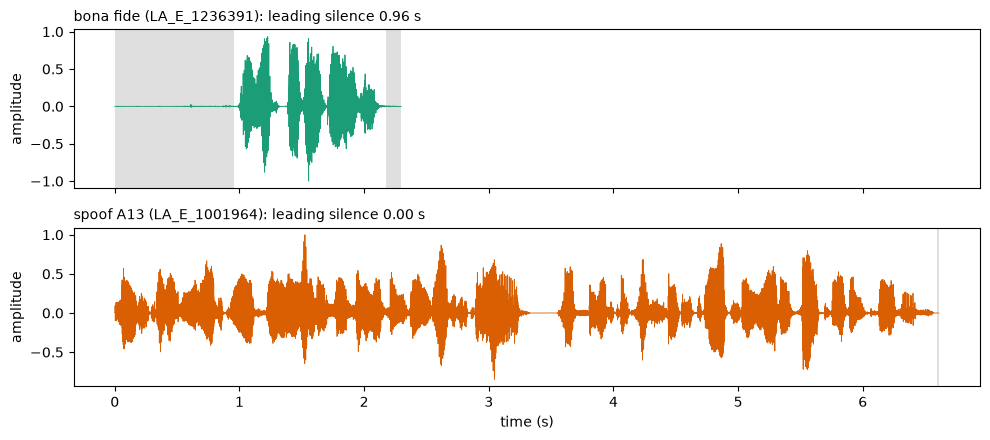

In [6]:
def typical(df):
    return df.loc[(df.lead_s - df.lead_s.median()).abs().idxmin()]

examples = [typical(ev[ev.label == "bonafide"]),
            typical(ev[ev.attack_id.isin([f"A{i}" for i in range(7, 17)])])]

fig, axes = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
for ax, row in zip(axes, examples):
    x = load_audio(row.path, SR)
    t = np.arange(len(x)) / SR
    ax.plot(t, x, color=CLASS_COLORS[row.label], linewidth=0.6)
    ax.axvspan(0, row.lead_s, color="grey", alpha=0.25, linewidth=0)
    ax.axvspan(t[-1] - row.trail_s, t[-1], color="grey", alpha=0.25, linewidth=0)
    name = "bona fide" if row.label == "bonafide" else f"spoof {row.attack_id}"
    ax.set_title(f"{name} ({row.utt_id}): leading silence {row.lead_s:.2f} s", loc="left", fontsize=10)
    ax.set_ylabel("amplitude")
axes[-1].set_xlabel("time (s)")
fig.tight_layout()

### Leading silence by class
Same measure on eval (10,000-clip clean subset) and ITW (5,000-clip subset), clipped at 2 s.

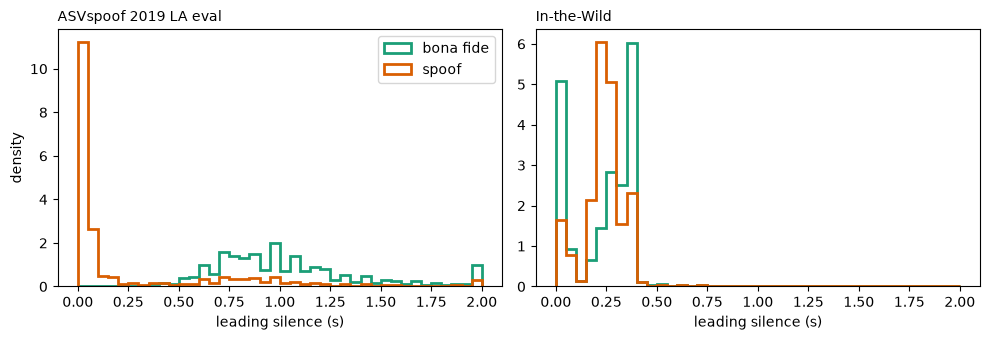

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True)
bins = np.linspace(0, 2, 41)
for ax, (name, df) in zip(axes, [("ASVspoof 2019 LA eval", ev), ("In-the-Wild", itw)]):
    for label, text in [("bonafide", "bona fide"), ("spoof", "spoof")]:
        ax.hist(df[df.label == label].lead_s.clip(upper=2), bins=bins, density=True, histtype="step",
                linewidth=2, color=CLASS_COLORS[label], label=text)
    ax.set_title(name, loc="left", fontsize=10)
    ax.set_xlabel("leading silence (s)")
axes[0].set_ylabel("density")
axes[0].legend()
fig.tight_layout()

### ROC of leading silence alone
No model and no training: the score is the leading-silence length itself (longer = bona fide). The first
run's A2 on the same eval clips is drawn for reference.

,score,auc,eer
0,"leading silence, eval",0.893,0.181
1,"leading silence, ITW",0.547,0.444
2,"trailing silence, eval",0.698,0.375
3,"first-run A2, eval",1.000,0.009


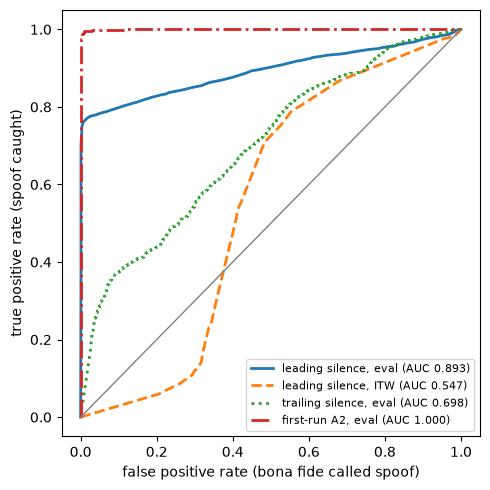

In [8]:
a2_raw = pd.read_csv("../runs/E-20261001-e1-a2-raw/scores/eval.csv").set_index("clip_id").score

curves = {
    "leading silence, eval": (ev.lead_s, ev.label),
    "leading silence, ITW": (itw.lead_s, itw.label),
    "trailing silence, eval": (ev.trail_s, ev.label),
    "first-run A2, eval": (a2_raw.reindex(ev.utt_id).values, ev.label),
}
fig, ax = plt.subplots(figsize=(5, 5))
rows = []
for (name, (score, label)), style in zip(curves.items(), ["-", "--", ":", "-."]):
    fpr, tpr, _ = roc_curve(label == "spoof", -np.asarray(score))
    auc = roc_auc(score, label, higher_is_spoof=False)
    ax.plot(fpr, tpr, linestyle=style, linewidth=2, label=f"{name} (AUC {auc:.3f})")
    rows.append({"score": name, "auc": auc, "eer": compute_eer(score, label, higher_is_spoof=False)[0]})
ax.plot([0, 1], [0, 1], color="grey", linewidth=1)
ax.set_xlabel("false positive rate (bona fide called spoof)")
ax.set_ylabel("true positive rate (spoof caught)")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
pd.DataFrame(rows).round(3)

Leading silence alone gets AUC 0.89 on eval, without listening to any speech. On ITW it is 0.55, close to
chance: that shortcut does not exist outside ASVspoof, so a model leaning on it has nothing to lean on there.

### Per attack: shortcut strength vs. what trimming cost the first run
Silence-only AUC for each eval attack against all bona fide clips, next to the first run's EER (%) on raw and
trimmed eval audio (models trained on raw audio, `reports/tables/E3_per_attack.csv`). Shaded = A17–A19.

In [9]:
bona = ev[ev.label == "bonafide"]
per_attack = pd.DataFrame([
    {"attack_id": a, "median_lead_s": g.lead_s.median(),
     "silence_auc": roc_auc(pd.concat([bona, g]).lead_s, pd.concat([bona, g]).label, higher_is_spoof=False)}
    for a, g in ev[ev.label == "spoof"].groupby("attack_id")
]).set_index("attack_id")
per_attack["group"] = np.where(per_attack.silence_auc > 0.9, "silence-separable", "bona-fide-like silence")

e3 = pd.read_csv("../reports/tables/E3_per_attack.csv").set_index(["system", "silence_mode"])
for system in ["a1", "a2"]:
    for mode in ["raw", "trimmed"]:
        per_attack[f"{system}_{mode}_eer"] = e3.loc[(system, mode), per_attack.index].astype(float) * 100
    per_attack[f"{system}_rise"] = per_attack[f"{system}_trimmed_eer"] - per_attack[f"{system}_raw_eer"]
display(per_attack.round(2))
per_attack.groupby("group")[["silence_auc", "a1_rise", "a2_rise"]].median().round(2)

,median_lead_s,silence_auc,group,a1_raw_eer,a1_trimmed_eer,a1_rise,a2_raw_eer,a2_trimmed_eer,a2_rise
attack_id,,,,,,,,,
A07,0.03,1.00,silence-separable,15.40,27.33,11.92,0.20,13.51,13.31
A08,0.16,0.99,silence-separable,0.26,0.72,0.45,0.59,7.12,6.54
A09,0.03,1.00,silence-separable,0.00,0.20,0.20,0.00,1.29,1.29
A10,0.00,1.00,silence-separable,22.42,36.73,14.31,2.00,39.54,37.54
A11,0.00,1.00,silence-separable,0.14,1.51,1.37,0.16,9.53,9.36
A12,0.00,1.00,silence-separable,7.61,36.02,28.41,0.08,10.77,10.69
A13,0.00,1.00,silence-separable,12.82,24.91,12.09,0.00,0.69,0.69
A14,0.03,1.00,silence-separable,1.14,3.74,2.60,0.37,17.83,17.46
A15,0.03,1.00,silence-separable,2.81,6.13,3.32,0.51,17.89,17.38


,silence_auc,a1_rise,a2_rise
group,,,
bona-fide-like silence,0.54,-1.55,3.66
silence-separable,1.00,7.62,10.02


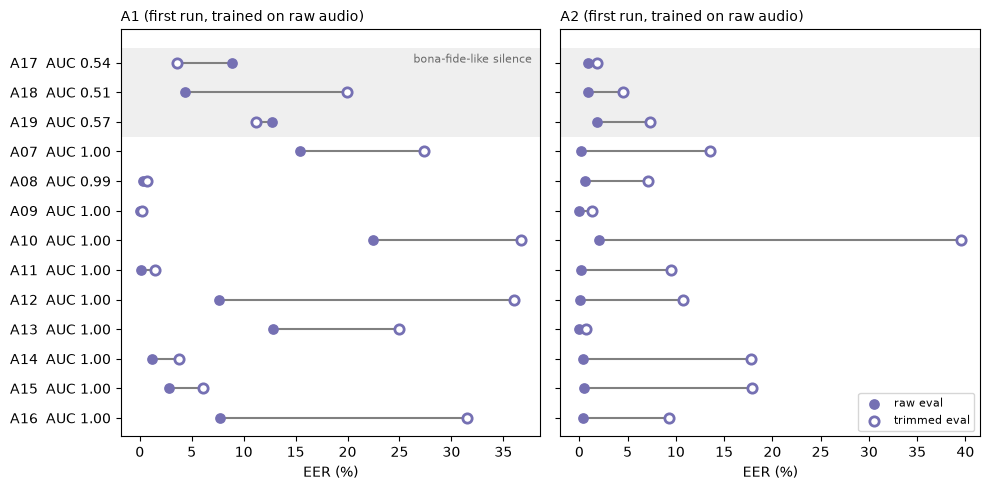

In [10]:
order = per_attack.sort_values(["group", "attack_id"], ascending=[False, False]).index
y = np.arange(len(order))
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
for ax, system in zip(axes, ["a1", "a2"]):
    raw, trim = per_attack.loc[order, f"{system}_raw_eer"], per_attack.loc[order, f"{system}_trimmed_eer"]
    ax.hlines(y, raw, trim, color="grey", linewidth=1.5)
    ax.scatter(raw, y, s=45, color="#7570b3", zorder=3, label="raw eval")
    ax.scatter(trim, y, s=45, facecolor="white", edgecolor="#7570b3", linewidth=2, zorder=3, label="trimmed eval")
    ax.axhspan(len(y) - 3.5, len(y) - 0.5, color="grey", alpha=0.12, linewidth=0)
    ax.set_title(f"{system.upper()} (first run, trained on raw audio)", loc="left", fontsize=10)
    ax.set_xlabel("EER (%)")
axes[0].set_yticks(y, [f"{a}  AUC {per_attack.silence_auc[a]:.2f}" for a in order])
axes[0].text(0.98, len(y) - 1, "bona-fide-like silence", transform=axes[0].get_yaxis_transform(), ha="right", fontsize=8,
             color="dimgray")
axes[1].legend(loc="lower right", fontsize=8)
fig.tight_layout()

For A2 the damage follows the shortcut. On the ten attacks leading silence separates (A07–A16, AUC ≥ 0.99)
trimming raised EER by a median of about 10 points, up to 37.5 on A10 (2.0% → 39.5%). On A17–A19, whose
silence looks like bona fide (AUC 0.51–0.57), the rise was 0.9–5.5 points. A1 is noisier: its median rise is
also clearly higher on A07–A16, but A18 rose 15.6 points with no silence gap to exploit, so trimming changes
more for A1 than silence alone. Part of every rise is also train/test mismatch, since these models never saw
trimmed audio.

### Did the first-run scores track silence?
Spearman correlation between each model's score (higher = bona fide) and the clip's raw leading silence, within
each class so the class difference itself cannot drive it. Positive rho on raw audio means more silence pushed
the score toward bona fide; on trimmed audio that link disappears or reverses.

In [11]:
runs = {"A1 raw": "E-20261001-e1-a1-raw", "A1 trimmed": "E-20261001-e1-a1-trimmed",
        "A2 raw": "E-20261001-e1-a2-raw", "A2 trimmed": "E-20261001-e1-a2-trimmed"}
rows = []
for name, run in runs.items():
    score = pd.read_csv(f"../runs/{run}/scores/eval.csv").set_index("clip_id").score.reindex(ev.utt_id).values
    df = ev.assign(score=score)
    rows.append({"scores": name, **{f"rho_{label}": spearmanr(g.score, g.lead_s)[0]
                                    for label, g in df.groupby("label")}})
pd.DataFrame(rows).set_index("scores").round(3)

,rho_bonafide,rho_spoof
scores,,
A1 raw,0.124,0.085
A1 trimmed,-0.033,-0.179
A2 raw,0.217,0.295
A2 trimmed,0.098,-0.238


**Conclusion.** The first run's eval numbers were inflated by a dataset artifact. Leading silence alone is a
strong eval classifier (AUC 0.89, EER 18%), both first-run models' scores follow it within each class, and
removing it at test time hurt A2 most on exactly the attacks it separates. On ITW the artifact is gone (AUC
0.55), so a model relying on it has nothing to fall back on there, which is part of why A1 fell to 58% EER.